# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
MB = 1024 ** 2

# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 16 / 8 / MB            # 16 bits = 2 bytes per voxel

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)      # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3: one ray per x-z pixel, one sample per voxel step along y
samples_per_frame = 512 * 300 * 512
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")


78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_ If the software drew every voxel as a geometric square (aspect = 1) instead of correcting for the
0.5 x 0.5 x 1.0 mm spacing, the coronal and sagittal views — both of which contain the thicker z axis — would come
out vertically stretched, so round structures like a vessel cross-section or the tumour itself would look taller and
narrower than they really are. Second, any on-screen measurement a radiologist takes with a ruler tool (say, the
tumour's height) would be physically wrong by the same distortion factor, even though the axial view (which never
mixes the z axis with the in-plane axes) would look fine — exactly the anisotropic-voxel trap the lecture warns
about.


## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

Lesion centroid (z, y, x) = (28, 40, 41)


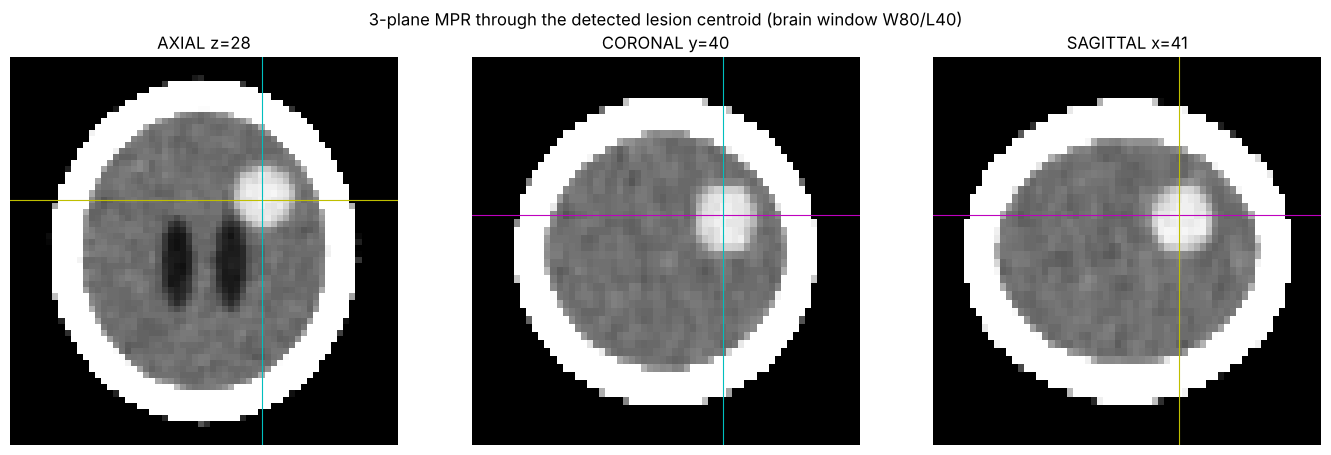

[Evaluation only] distance from true tumour centroid: 2.92 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1
bone_mask = vol > 300
inside = ndimage.binary_fill_holes(bone_mask) & ~bone_mask
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = inside & (vol > 55) & (vol < 90)

# TODO 2
comp, n_comp = ndimage.label(candidates)
sizes = np.bincount(comp.ravel())
sizes[0] = 0                                     # ignore background label 0
largest_label = sizes.argmax()
lesion = comp == largest_label
cz, cy, cx = np.round(np.argwhere(lesion).mean(axis=0)).astype(int)
print(f"Lesion centroid (z, y, x) = ({cz}, {cy}, {cx})")

# TODO 3
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
axes[0].imshow(window(vol[cz], 80, 40), cmap="gray", origin="lower")
axes[0].axhline(cy, color="y", lw=0.8); axes[0].axvline(cx, color="c", lw=0.8)
axes[0].set_title(f"AXIAL z={cz}"); axes[0].axis("off")

axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap="gray", origin="lower", aspect=ASPECT)
axes[1].axhline(cz, color="m", lw=0.8); axes[1].axvline(cx, color="c", lw=0.8)
axes[1].set_title(f"CORONAL y={cy}"); axes[1].axis("off")

axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap="gray", origin="lower", aspect=ASPECT)
axes[2].axhline(cz, color="m", lw=0.8); axes[2].axvline(cy, color="y", lw=0.8)
axes[2].set_title(f"SAGITTAL x={cx}"); axes[2].axis("off")

plt.suptitle("3-plane MPR through the detected lesion centroid (brain window W80/L40)")
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
true_centroid = np.argwhere(labels == 5).mean(axis=0)
dist_mm = np.linalg.norm((np.array([cz, cy, cx]) - true_centroid) * np.array(SPACING))
print(f"[Evaluation only] distance from true tumour centroid: {dist_mm:.2f} mm")


**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_ Right under the skull, voxels sit on the boundary between bone and brain tissue, so each one averages
the HU of both materials inside that voxel — the **partial-volume effect**. That averaging produces a thin shell of
voxels whose HU happens to fall inside the 55-90 range we're using to hunt for the lesion, purely because they are
part-bone/part-brain, not because they're tumour. This is exactly the "overlapping intensity ranges" problem from
Slide 28: the same HU value can belong to more than one tissue type depending on context. Eroding the brain mask by
a few voxels strips away that unreliable boundary shell before we search, so the 55-90 HU candidates we keep are
much more likely to be genuine lesion tissue deep inside the brain rather than a skull/brain partial-volume
artifact.


## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold_hu,voxels,volume_ml,dice_vs_truth
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


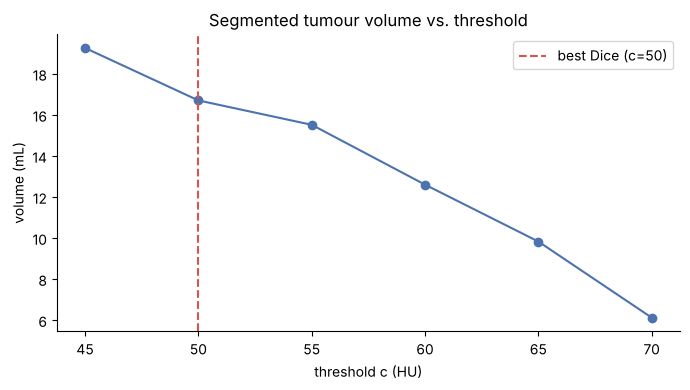

Volume ranges from 6.12 mL (c=70) to 19.26 mL (c=45) across thresholds 45-70 HU. Best-matching-ground-truth estimate: 16.70 mL at c=50 HU (Dice=0.99).


In [4]:
truth = labels == 5
rows = []
# TODO 1 & 2
for c in [45, 50, 55, 60, 65, 70]:
    comp, _ = ndimage.label(vol > c)
    region = comp == comp[cz, cy, cx]
    voxels = int(region.sum())
    volume_ml = voxels * VOXEL_MM3 / 1000
    dice = 2 * (region & truth).sum() / (region.sum() + truth.sum())
    rows.append({"threshold_hu": c, "voxels": voxels, "volume_ml": volume_ml, "dice_vs_truth": dice})

table = pd.DataFrame(rows)
display(table)

# TODO 3
best = table.loc[table.dice_vs_truth.idxmax()]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table.threshold_hu, table.volume_ml, "o-", color="#4C72B0")
ax.axvline(best.threshold_hu, color="#D9534F", ls="--", label=f"best Dice (c={best.threshold_hu:.0f})")
ax.set_xlabel("threshold c (HU)"); ax.set_ylabel("volume (mL)")
ax.set_title("Segmented tumour volume vs. threshold"); ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(f"Volume ranges from {table.volume_ml.min():.2f} mL (c={table.loc[table.volume_ml.idxmin(), 'threshold_hu']:.0f}) "
      f"to {table.volume_ml.max():.2f} mL (c={table.loc[table.volume_ml.idxmax(), 'threshold_hu']:.0f}) across thresholds 45-70 HU. "
      f"Best-matching-ground-truth estimate: {best.volume_ml:.2f} mL at c={best.threshold_hu:.0f} HU (Dice={best.dice_vs_truth:.2f}).")


**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_ Without ground truth, I'd pick c from the biology, not from a Dice score: the lecture's histogram of
brain vs. tumour HU values (Task 2's overlap) shows where the two distributions cross over, and a reasonable
default sits near the middle of that crossover band rather than at either extreme, ideally checked against a few
similar prior cases. To visualize the uncertainty, I would never report a single mL figure — instead I'd show the
volume-vs-threshold curve from this task directly to the board (volume rises or falls smoothly as c moves), and
state the tumour volume as the range spanned by a clinically plausible window of thresholds (e.g. 55-65 HU) rather
than one number, so the surgeon sees explicitly how sensitive the estimate is to where the line was drawn.


## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

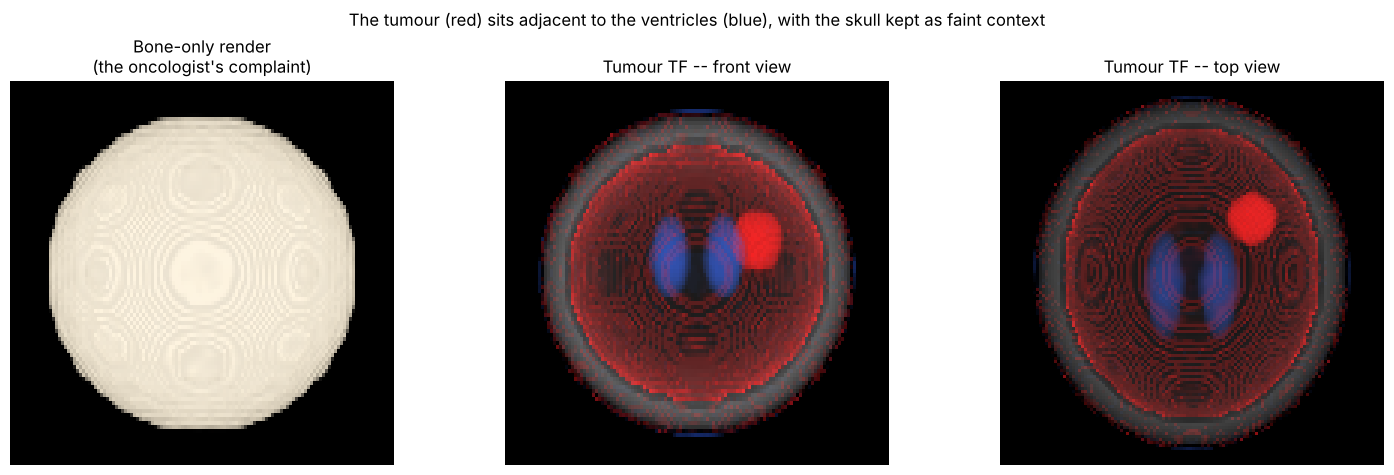

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0),
    (-200,  (0, 0, 0), 0),          # air / soft tissue: transparent
    (0,     (0, 0, 0), 0),
    (5,     (0.2, 0.4, 1.0), 0.03), # CSF: faint blue
    (20,    (0.2, 0.4, 1.0), 0.03),
    (30,    (0, 0, 0), 0),
    (55,    (0, 0, 0), 0),
    (65,    (1.0, 0.1, 0.1), 0.15), # tumour: red
    (80,    (1.0, 0.1, 0.1), 0.15),
    (95,    (0, 0, 0), 0),
    (300,   (1, 1, 1), 0.0),
    (400,   (1, 1, 1), 0.008),      # bone: almost transparent, just for context
    (1500,  (1, 1, 1), 0.008),
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
C_bone, _ = render(vol, bone_tf, axis=1)
axes[0].imshow(np.clip(C_bone, 0, 1), origin="lower", aspect=ASPECT)
axes[0].set_title("Bone-only render\n(the oncologist's complaint)"); axes[0].axis("off")

C_front, _ = render(vol, tumour_tf, axis=1)
axes[1].imshow(np.clip(C_front, 0, 1), origin="lower", aspect=ASPECT)
axes[1].set_title("Tumour TF -- front view"); axes[1].axis("off")

C_top, _ = render(vol, tumour_tf, axis=0)
axes[2].imshow(np.clip(C_top, 0, 1), origin="lower")
axes[2].set_title("Tumour TF -- top view"); axes[2].axis("off")

# TODO 4: suptitle
fig.suptitle("The tumour (red) sits adjacent to the ventricles (blue), with the skull kept as faint context")
plt.tight_layout(); plt.show()


**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_ That faint red rim is the same **partial-volume effect** from Task 2: voxels right under the skull
blend bone and brain HU values, and some of those blended values land inside the 65-80 HU range the transfer
function paints red, so the TF lights them up as if they were tumour. A transfer function alone can't fix this
because it only ever looks at a voxel's intensity, with no notion of *where* that voxel sits in the volume — it
cannot tell a true tumour voxel apart from a skull-boundary voxel that happens to share the same HU. What would
remove it is **segmentation** (Slides 31-32): first identify the actual tumour region with a spatial method (e.g.
the connected-component growth used in Task 3, anchored at a location known to be inside the brain), then render or
colour only that segmented mask, rather than painting every voxel in a given intensity band regardless of position.


## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_ The lesion sits deep in the brain at the centroid we located in Task 2, with an estimated
volume of roughly 6 to 19 mL depending on exactly where the intensity threshold is drawn (Task 3 shows it is not a single
exact number, but a range that shifts smoothly as the threshold moves from 45 to 70 HU, with our best estimate near
16-17 mL). I'd open tomorrow's meeting
with the **3-plane MPR** (Task 2): a direct 3-D render would hide the lesion behind the skull unless carefully tuned
("occlusion" is the volume renderer's main enemy per Slide 28), while slicing the volume exposes the internal
structure directly and lets everyone see the lesion in its anatomical context in all three planes at once. The 3-D
render is still valuable afterward for showing the tumour's relation to the ventricles in one picture, but the board
should keep in mind that its colours come from a threshold-based transfer function, which — because of the same
intensity overlap between bone, brain and tumour discussed in Task 4 — can both miss true tumour voxels and light up
non-tumour voxels that merely share the same HU range, so it should never be read as a precise measurement tool.
